## Looking into the land constant data for SMAP

In [1]:
import pandas as pd 
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import h5py

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/base_savio/share/proj failed


In [2]:
file_path='/global/scratch/users/toireasamarie/SMAP/SMAP_test_files/SMAP_L4_SM_lmc_00000000T000000_Tv7031_001.h5'
file=h5py.File(file_path,'r')

#lmc stands for land model constants

In [3]:
def print_h5_structure(name, obj):
    print(name)

with h5py.File(file_path, 'r') as file:
    print("file structure:")
    file.visititems(print_h5_structure)

file structure:
EASE2_global_projection
Land-Model-Constants_Data
Land-Model-Constants_Data/cell_elevation
Land-Model-Constants_Data/cell_land_fraction
Land-Model-Constants_Data/clsm_cdcr1
Land-Model-Constants_Data/clsm_cdcr2
Land-Model-Constants_Data/clsm_dzgt1
Land-Model-Constants_Data/clsm_dzgt2
Land-Model-Constants_Data/clsm_dzgt3
Land-Model-Constants_Data/clsm_dzgt4
Land-Model-Constants_Data/clsm_dzgt5
Land-Model-Constants_Data/clsm_dzgt6
Land-Model-Constants_Data/clsm_dzpr
Land-Model-Constants_Data/clsm_dzrz
Land-Model-Constants_Data/clsm_dzsf
Land-Model-Constants_Data/clsm_dztsurf
Land-Model-Constants_Data/clsm_poros
Land-Model-Constants_Data/clsm_veghght
Land-Model-Constants_Data/clsm_wp
Land-Model-Constants_Data/mwrtm_bh
Land-Model-Constants_Data/mwrtm_bv
Land-Model-Constants_Data/mwrtm_clay
Land-Model-Constants_Data/mwrtm_lewt
Land-Model-Constants_Data/mwrtm_omega
Land-Model-Constants_Data/mwrtm_poros
Land-Model-Constants_Data/mwrtm_rghhmax
Land-Model-Constants_Data/mwrtm_rgh

In [4]:
with h5py.File(file_path, 'r') as file:
    dataset = file['Land-Model-Constants_Data/clsm_poros']
    print("shape:", dataset.shape)
    print("data type:", dataset.dtype)
    print("attributes:", dict(dataset.attrs))

shape: (1624, 3856)
data type: float32
attributes: {'DIMENSION_LABELS': array([b'y', b'x'], dtype='|S1'), 'DIMENSION_LIST': array([array([<HDF5 object reference>], dtype=object),
       array([<HDF5 object reference>], dtype=object)], dtype=object), '_FillValue': -9999.0, 'coordinates': b'/cell_lat /cell_lon', 'fmissing_value': -9999.0, 'grid_mapping': b'EASE2_global_projection', 'long_name': b'Catchment model: Soil porosity', 'missing_value': -9999.0, 'units': b'm3 m-3', 'valid_max': 0.93, 'valid_min': 0.3}


In [5]:
with h5py.File(file_path, 'r') as file:
    dataset = file['Land-Model-Constants_Data/mwrtm_poros']
    print("shape:", dataset.shape)
    print("data type:", dataset.dtype)
    print("attributes:", dict(dataset.attrs))

shape: (1624, 3856)
data type: float32
attributes: {'DIMENSION_LABELS': array([b'y', b'x'], dtype='|S1'), 'DIMENSION_LIST': array([array([<HDF5 object reference>], dtype=object),
       array([<HDF5 object reference>], dtype=object)], dtype=object), '_FillValue': -9999.0, 'coordinates': b'/cell_lat /cell_lon', 'fmissing_value': -9999.0, 'grid_mapping': b'EASE2_global_projection', 'long_name': b'Microwave radiative transfer model: Porosity', 'missing_value': -9999.0, 'units': b'm3 m-3', 'valid_max': 0.93, 'valid_min': 0.3}


In [6]:
with h5py.File(file_path, 'r') as f:
    catchment_model_porosity= f['Land-Model-Constants_Data/clsm_poros'][:]
    microwave_model_porosity= f['Land-Model-Constants_Data/mwrtm_poros'][:]
    cell_lat = f['cell_lat'][:]
    cell_lon = f['cell_lon'][:]
    time = f['time'][:]

#.ravel() will flatten multi D arrays to 1D
porosity_df = pd.DataFrame({'latitude': cell_lat.ravel(),
                   'longitude': cell_lon.ravel(),
                   'time': np.full(cell_lat.size, time[0]),  #same time for all points because one file has one time for everything
                   'catchment_model_porosity': catchment_model_porosity.ravel(),
                   'microwave_model_porosity': microwave_model_porosity.ravel()})

porosity_df['datetime'] = pd.to_datetime(porosity_df['time'], unit='s', origin='2000-01-01 11:58:55.816')
porosity_df.drop(columns='time', inplace=True)

In [7]:
porosity_df

,latitude,longitude,catchment_model_porosity,microwave_model_porosity,datetime
0,84.656441,-179.953323,-9999.0,-9999.0,2025-02-14 23:58:55
1,84.656441,-179.859970,-9999.0,-9999.0,2025-02-14 23:58:55
2,84.656441,-179.766602,-9999.0,-9999.0,2025-02-14 23:58:55
3,84.656441,-179.673248,-9999.0,-9999.0,2025-02-14 23:58:55
4,84.656441,-179.579880,-9999.0,-9999.0,2025-02-14 23:58:55
...,...,...,...,...,...
6262139,-84.656441,179.579880,-9999.0,-9999.0,2025-02-14 23:58:55
6262140,-84.656441,179.673248,-9999.0,-9999.0,2025-02-14 23:58:55
6262141,-84.656441,179.766602,-9999.0,-9999.0,2025-02-14 23:58:55
6262142,-84.656441,179.859970,-9999.0,-9999.0,2025-02-14 23:58:55


In [8]:
lon_min, lon_max=-104,-80
lat_min, lat_max =36,49

midwest_porosity_df = porosity_df[(porosity_df['latitude'] > lat_min) & (porosity_df['latitude'] < lat_max) &
(porosity_df['longitude'] > lon_min) & (porosity_df['longitude'] < lon_max)]

midwest_porosity_df

,latitude,longitude,catchment_model_porosity,microwave_model_porosity,datetime
764302,48.951267,-103.957474,0.3963,0.4351,2025-02-14 23:58:55
764303,48.951267,-103.864113,0.4352,0.4584,2025-02-14 23:58:55
764304,48.951267,-103.770752,0.4352,0.4584,2025-02-14 23:58:55
764305,48.951267,-103.677391,0.4352,0.4584,2025-02-14 23:58:55
764306,48.951267,-103.584030,0.4352,0.4584,2025-02-14 23:58:55
...,...,...,...,...,...
1285114,36.070938,-80.430504,0.4942,0.4063,2025-02-14 23:58:55
1285115,36.070938,-80.337143,0.4942,0.4063,2025-02-14 23:58:55
1285116,36.070938,-80.243782,0.4554,0.4457,2025-02-14 23:58:55
1285117,36.070938,-80.150421,0.5463,0.4063,2025-02-14 23:58:55


In [9]:
missing_value = -9999

midwest_porosity_df['catchment_model_porosity'] = midwest_porosity_df['catchment_model_porosity'].replace(missing_value, np.nan)
midwest_porosity_df['microwave_model_porosity'] = midwest_porosity_df['microwave_model_porosity'].replace(missing_value, np.nan)
midwest_porosity_df = midwest_porosity_df.dropna(subset=['catchment_model_porosity', 'microwave_model_porosity'])

/tmp/ipykernel_99342/785107435.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  midwest_porosity_df['catchment_model_porosity'] = midwest_porosity_df['catchment_model_porosity'].replace(missing_value, np.nan)
/tmp/ipykernel_99342/785107435.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  midwest_porosity_df['microwave_model_porosity'] = midwest_porosity_df['microwave_model_porosity'].replace(missing_value, np.nan)


In [10]:
midwest_porosity_df

,latitude,longitude,catchment_model_porosity,microwave_model_porosity,datetime
764302,48.951267,-103.957474,0.3963,0.4351,2025-02-14 23:58:55
764303,48.951267,-103.864113,0.4352,0.4584,2025-02-14 23:58:55
764304,48.951267,-103.770752,0.4352,0.4584,2025-02-14 23:58:55
764305,48.951267,-103.677391,0.4352,0.4584,2025-02-14 23:58:55
764306,48.951267,-103.584030,0.4352,0.4584,2025-02-14 23:58:55
...,...,...,...,...,...
1285114,36.070938,-80.430504,0.4942,0.4063,2025-02-14 23:58:55
1285115,36.070938,-80.337143,0.4942,0.4063,2025-02-14 23:58:55
1285116,36.070938,-80.243782,0.4554,0.4457,2025-02-14 23:58:55
1285117,36.070938,-80.150421,0.5463,0.4063,2025-02-14 23:58:55


In [11]:
print('Statistics for the catchment model porosity are:')
midwest_porosity_df['catchment_model_porosity'].describe()

Statistics for the catchment model porosity are:


count    32614.000000
mean         0.469940
std          0.092486
min          0.374100
25%          0.421400
50%          0.452700
75%          0.494200
max          0.930000
Name: catchment_model_porosity, dtype: float64

In [12]:
print('Statistics for the microwave radiative transfer model porosity are:')
midwest_porosity_df['microwave_model_porosity'].describe()

Statistics for the microwave radiative transfer model porosity are:


count    32614.000000
mean         0.474796
std          0.087083
min          0.374100
25%          0.440000
50%          0.458400
75%          0.485700
max          0.930000
Name: microwave_model_porosity, dtype: float64

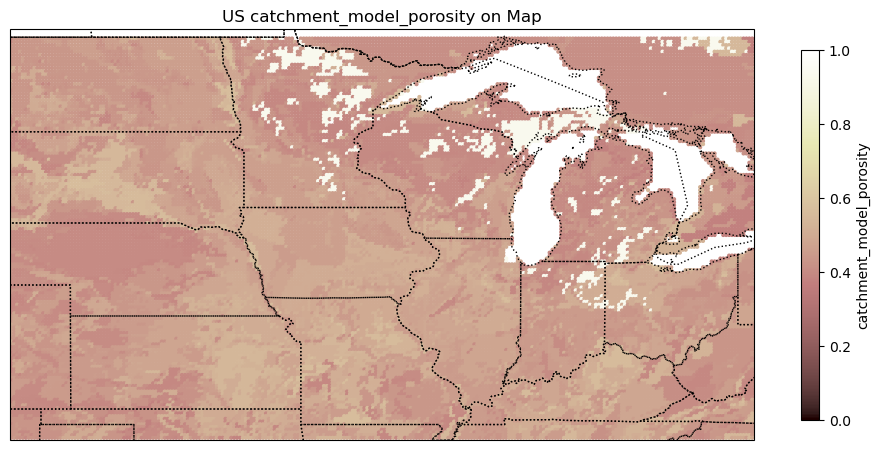

In [13]:
#plotting catchment model porosity first
sm_variable ='catchment_model_porosity'

plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(midwest_porosity_df['longitude'], midwest_porosity_df['latitude'],
                c=midwest_porosity_df[sm_variable],
                cmap='pink',
                s=4,
                transform=ccrs.PlateCarree(),
               vmin=0, 
               vmax=1)


cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f'{sm_variable}')

ax.set_title(f'US {sm_variable} on Map')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

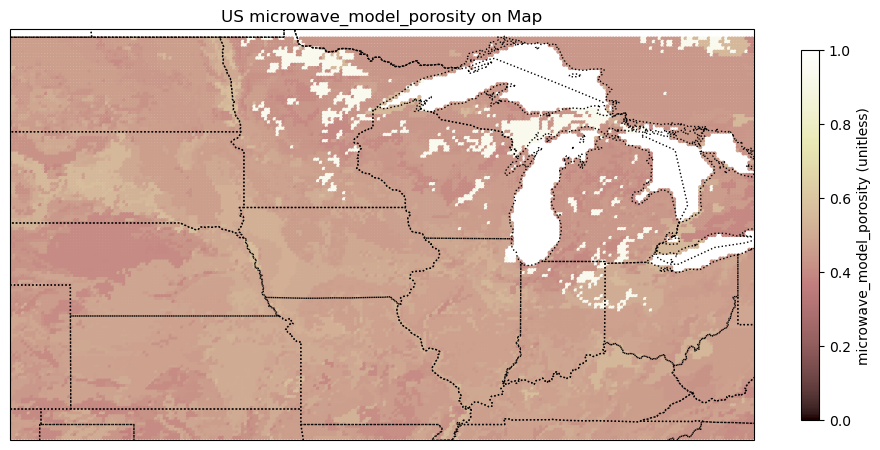

In [14]:
#plotting catchment model porosity first

sm_variable ='microwave_model_porosity'

plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(midwest_porosity_df['longitude'], midwest_porosity_df['latitude'],
                c=midwest_porosity_df[sm_variable],
                cmap='pink',
                s=4,
                vmin=0,
                vmax=1,
                transform=ccrs.PlateCarree())


cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f'{sm_variable} (unitless)')

ax.set_title(f'US {sm_variable} on Map')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

In [15]:
midwest_porosity_df['diff_c-m'] = midwest_porosity_df['catchment_model_porosity'] - midwest_porosity_df['microwave_model_porosity']
midwest_porosity_df

/tmp/ipykernel_99342/1315110232.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  midwest_porosity_df['diff_c-m'] = midwest_porosity_df['catchment_model_porosity'] - midwest_porosity_df['microwave_model_porosity']


,latitude,longitude,catchment_model_porosity,microwave_model_porosity,datetime,diff_c-m
764302,48.951267,-103.957474,0.3963,0.4351,2025-02-14 23:58:55,-0.0388
764303,48.951267,-103.864113,0.4352,0.4584,2025-02-14 23:58:55,-0.0232
764304,48.951267,-103.770752,0.4352,0.4584,2025-02-14 23:58:55,-0.0232
764305,48.951267,-103.677391,0.4352,0.4584,2025-02-14 23:58:55,-0.0232
764306,48.951267,-103.584030,0.4352,0.4584,2025-02-14 23:58:55,-0.0232
...,...,...,...,...,...,...
1285114,36.070938,-80.430504,0.4942,0.4063,2025-02-14 23:58:55,0.0879
1285115,36.070938,-80.337143,0.4942,0.4063,2025-02-14 23:58:55,0.0879
1285116,36.070938,-80.243782,0.4554,0.4457,2025-02-14 23:58:55,0.0097
1285117,36.070938,-80.150421,0.5463,0.4063,2025-02-14 23:58:55,0.1400


In [16]:
print('Statistics for the catchment model - radiative transfer model:')
midwest_porosity_df['diff_c-m'].describe()

Statistics for the catchment model - radiative transfer model:


count    32614.000000
mean        -0.004856
std          0.028938
min         -0.174800
25%         -0.025200
50%          0.000000
75%          0.008700
max          0.159200
Name: diff_c-m, dtype: float64

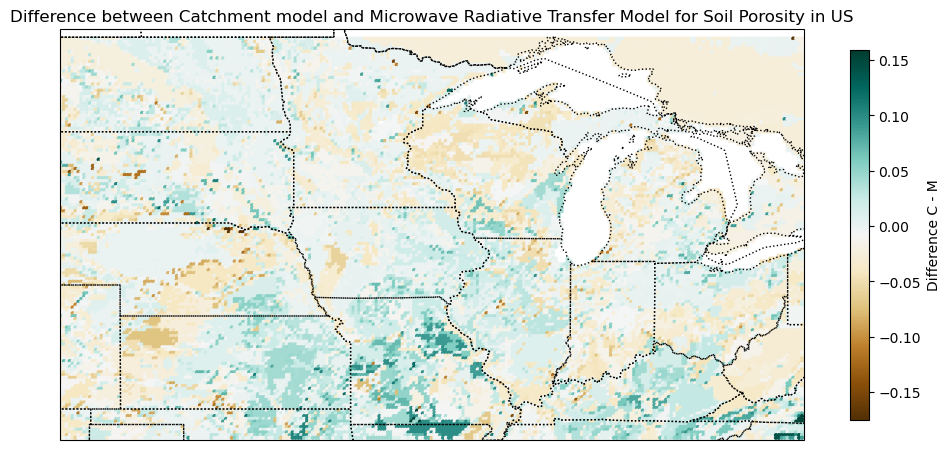

In [17]:
#plotting catchment model porosity first

plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(midwest_porosity_df['longitude'], midwest_porosity_df['latitude'],
                c=midwest_porosity_df['diff_c-m'],
                cmap='BrBG',
                s=4,
                transform=ccrs.PlateCarree())


cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f'Difference C - M')

ax.set_title(f'Difference between Catchment model and Microwave Radiative Transfer Model for Soil Porosity in US')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

### now insert SMAP-- soil moisture data to look at WFPS

In [23]:
smap_file = '/global/scratch/users/toireasamarie/SMAP/all_SMAP_202403-202407.parquet'
smap_df=pd.read_parquet(smap_file, engine='pyarrow')

In [24]:
sm_poros_df = pd.merge(
    smap_df,
    midwest_porosity_df,
    on=['latitude', 'longitude'],
    how='inner')            

In [25]:
sm_poros_df= sm_poros_df.drop(columns=['datetime_y'])

In [26]:
sm_poros_df['WFPS_c'] = sm_poros_df['sm_surface']/sm_poros_df['catchment_model_porosity']
sm_poros_df['WFPS_m'] = sm_poros_df['sm_surface']/sm_poros_df['microwave_model_porosity']

In [27]:
sm_poros_df

,latitude,longitude,sm_surface,sm_rootzone,surface_temp,soil_temp_layer1,LAI,datetime_x,catchment_model_porosity,microwave_model_porosity,diff_c-m,WFPS_c,WFPS_m
0,48.951267,-103.957474,0.087287,0.119180,282.964539,273.160004,0.042725,2024-02-29 22:28:55,0.3963,0.4351,-0.0388,0.220254,0.200613
1,48.951267,-103.864113,0.158729,0.200062,282.894318,273.160004,0.036697,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.364726,0.346267
2,48.951267,-103.770752,0.160134,0.201959,282.958588,273.160004,0.030681,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.367954,0.349332
3,48.951267,-103.677391,0.159644,0.203763,282.922485,273.160004,0.029179,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.366829,0.348264
4,48.951267,-103.584030,0.159519,0.203495,282.843567,273.160004,0.029720,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.366541,0.347990
...,...,...,...,...,...,...,...,...,...,...,...,...,...
39952145,36.070938,-80.430504,0.279432,0.318316,302.558807,301.026520,3.516579,2024-07-31 22:28:55,0.4942,0.4063,0.0879,0.565423,0.687748
39952146,36.070938,-80.337143,0.292319,0.306735,302.554413,301.201599,1.901240,2024-07-31 22:28:55,0.4942,0.4063,0.0879,0.591499,0.719466
39952147,36.070938,-80.243782,0.277417,0.295555,303.147797,302.106262,1.140026,2024-07-31 22:28:55,0.4554,0.4457,0.0097,0.609172,0.622430
39952148,36.070938,-80.150421,0.333433,0.362370,302.553680,301.206207,1.942417,2024-07-31 22:28:55,0.5463,0.4063,0.1400,0.610348,0.820658


In [28]:
sm_poros_df['WFPS_c'].describe()

count    3.995215e+07
mean     5.233042e-01
std      1.922517e-01
min      1.017725e-02
25%      4.046617e-01
50%      5.282497e-01
75%      6.566291e-01
max      9.999813e-01
Name: WFPS_c, dtype: float64

In [29]:
sm_poros_df['WFPS_m'].describe()

count    3.995215e+07
mean     5.207168e-01
std      1.997586e-01
min      8.647249e-03
25%      3.912083e-01
50%      5.205752e-01
75%      6.582915e-01
max      1.285006e+00
Name: WFPS_m, dtype: float64

In [30]:
sm_poros_df['WFPS_diff'] = sm_poros_df['WFPS_c']-sm_poros_df['WFPS_m']

In [31]:
regional_mean = sm_poros_df.groupby(['latitude', 'longitude'])[['WFPS_c', 'WFPS_m', 'WFPS_diff']].mean().reset_index()
regional_mean

,latitude,longitude,WFPS_c,WFPS_m,WFPS_diff
0,36.070938,-103.957474,0.332493,0.303262,0.029231
1,36.070938,-103.864113,0.387442,0.377975,0.009466
2,36.070938,-103.770752,0.354070,0.356738,-0.002668
3,36.070938,-103.677391,0.339683,0.334404,0.005279
4,36.070938,-103.584030,0.269105,0.245447,0.023658
...,...,...,...,...,...
32609,48.951267,-80.430504,0.771240,0.772939,-0.001699
32610,48.951267,-80.337143,0.499120,0.342796,0.156324
32611,48.951267,-80.243782,0.472328,0.450875,0.021453
32612,48.951267,-80.150421,0.470076,0.448725,0.021351


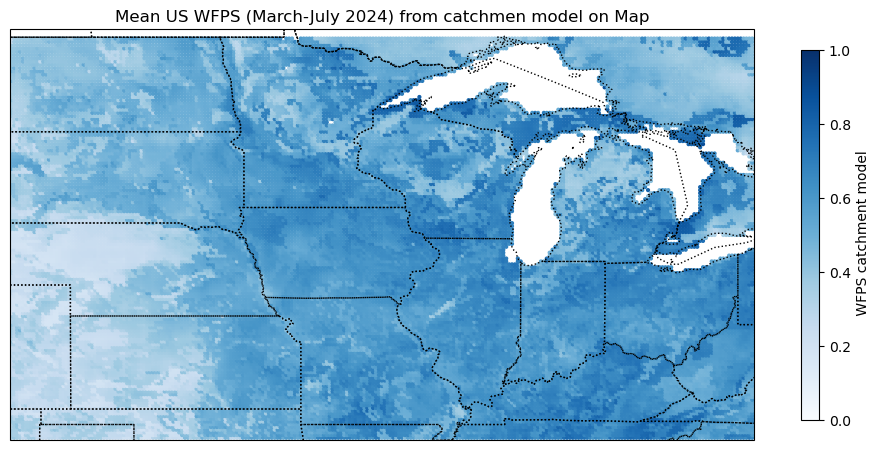

In [32]:
#plotting catchment model WFPS first

plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(regional_mean['longitude'], regional_mean['latitude'],
                c=regional_mean['WFPS_c'],
                cmap='Blues',
                s=4,
                transform=ccrs.PlateCarree(),
               vmin=0, 
               vmax=1)

cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f' WFPS catchment model')

ax.set_title(f'Mean US WFPS (March-July 2024) from catchmen model on Map')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

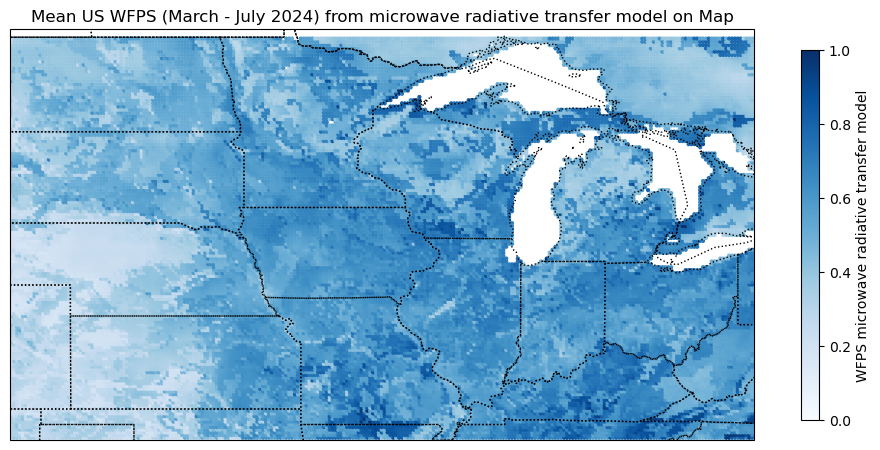

In [33]:
#plotting microwave model WFPS 

plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(regional_mean['longitude'], regional_mean['latitude'],
                c=regional_mean['WFPS_m'],
                cmap='Blues',
                s=4,
                transform=ccrs.PlateCarree(),
               vmin=0, 
               vmax=1)

cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f'WFPS microwave radiative transfer model')

ax.set_title(f'Mean US WFPS (March - July 2024) from microwave radiative transfer model on Map')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

In [34]:
sm_poros_df['WFPS_diff'].describe()

count    3.995215e+07
mean     2.587963e-03
std      3.411469e-02
min     -3.615640e-01
25%     -7.254720e-03
50%      0.000000e+00
75%      2.371716e-02
max      3.122413e-01
Name: WFPS_diff, dtype: float64

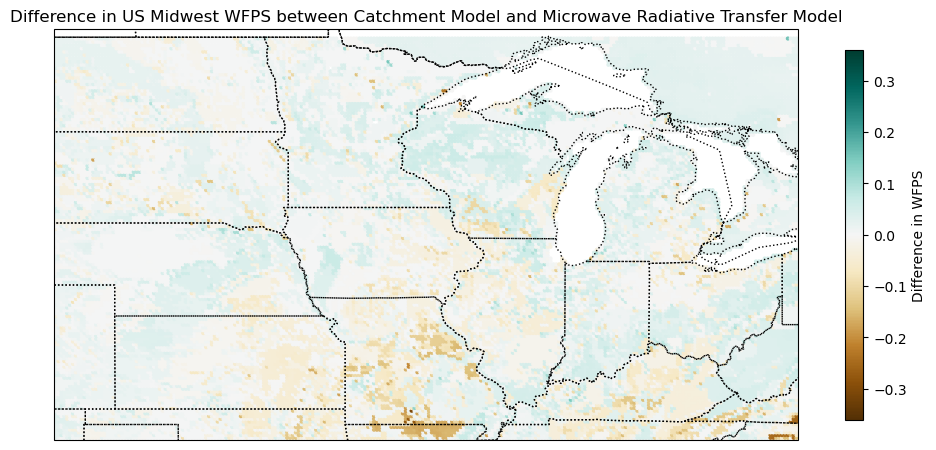

In [35]:
#plotting difference in WFPS

plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(regional_mean['longitude'], regional_mean['latitude'],
                c=regional_mean['WFPS_diff'],
                cmap='BrBG',
                s=4,
                transform=ccrs.PlateCarree(), 
               vmin=-0.36,
                vmax=0.36)

cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f'Difference in WFPS')

ax.set_title(f'Difference in US Midwest WFPS between Catchment Model and Microwave Radiative Transfer Model')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

In [36]:
sm_poros_df

,latitude,longitude,sm_surface,sm_rootzone,surface_temp,soil_temp_layer1,LAI,datetime_x,catchment_model_porosity,microwave_model_porosity,diff_c-m,WFPS_c,WFPS_m,WFPS_diff
0,48.951267,-103.957474,0.087287,0.119180,282.964539,273.160004,0.042725,2024-02-29 22:28:55,0.3963,0.4351,-0.0388,0.220254,0.200613,0.019641
1,48.951267,-103.864113,0.158729,0.200062,282.894318,273.160004,0.036697,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.364726,0.346267,0.018459
2,48.951267,-103.770752,0.160134,0.201959,282.958588,273.160004,0.030681,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.367954,0.349332,0.018622
3,48.951267,-103.677391,0.159644,0.203763,282.922485,273.160004,0.029179,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.366829,0.348264,0.018566
4,48.951267,-103.584030,0.159519,0.203495,282.843567,273.160004,0.029720,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.366541,0.347990,0.018551
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39952145,36.070938,-80.430504,0.279432,0.318316,302.558807,301.026520,3.516579,2024-07-31 22:28:55,0.4942,0.4063,0.0879,0.565423,0.687748,-0.122325
39952146,36.070938,-80.337143,0.292319,0.306735,302.554413,301.201599,1.901240,2024-07-31 22:28:55,0.4942,0.4063,0.0879,0.591499,0.719466,-0.127967
39952147,36.070938,-80.243782,0.277417,0.295555,303.147797,302.106262,1.140026,2024-07-31 22:28:55,0.4554,0.4457,0.0097,0.609172,0.622430,-0.013258
39952148,36.070938,-80.150421,0.333433,0.362370,302.553680,301.206207,1.942417,2024-07-31 22:28:55,0.5463,0.4063,0.1400,0.610348,0.820658,-0.210310


In [37]:
precip_file= '/global/scratch/users/toireasamarie/precip/mar-jul_precip.parquet'
precip=pd.read_parquet(precip_file,engine='pyarrow')

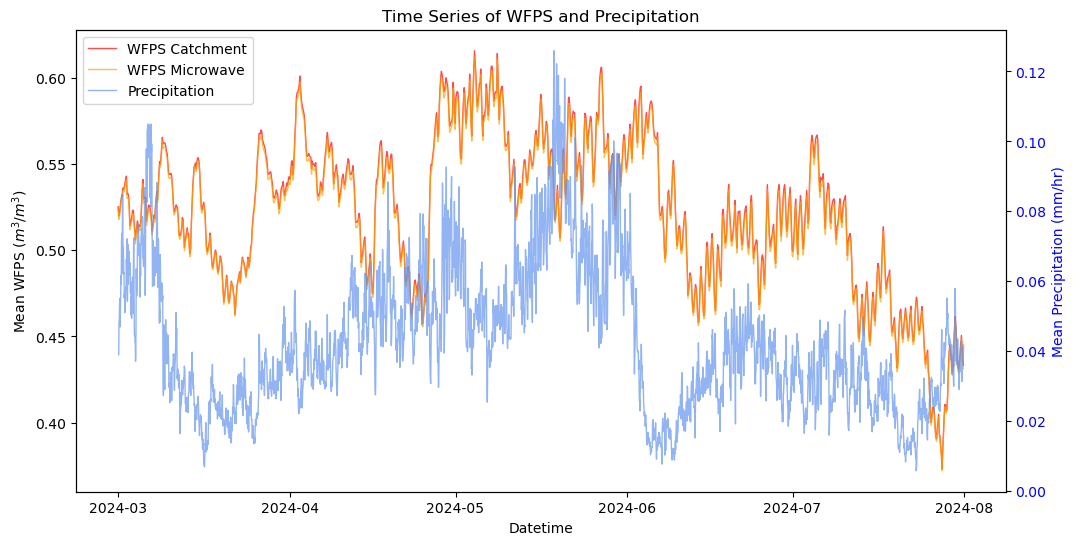

In [38]:
fig, ax1 = plt.subplots(figsize=(12, 6))
regional_mean = sm_poros_df.groupby('datetime_x')[['WFPS_c', 'WFPS_m','WFPS_diff']].mean().reset_index()
precip_mean = precip.groupby('hour')['h_precip'].mean().reset_index()

#SM on first y axis
ax1.plot(regional_mean['datetime_x'], regional_mean['WFPS_c'], label='WFPS Catchment', color='red', alpha=0.7,lw=1)
ax1.plot(regional_mean['datetime_x'], regional_mean['WFPS_m'], label='WFPS Microwave', color='orange',alpha =0.7,lw=1)

ax1.set_xlabel('Datetime')
ax1.set_ylabel(r'Mean WFPS ($m^3/m^3$)', color='black')
ax1.tick_params(axis='y', labelcolor='black')

#precip on second y axis
ax2 = ax1.twinx()
ax2.plot(precip_mean['hour'], precip_mean['h_precip'], label='Precipitation', color='cornflowerblue', alpha=0.7,lw=1)

ax2.set_ylabel('Mean Precipitation (mm/hr)', color='blue')
ax2.tick_params(axis='y', labelcolor='blue')

#combining legends 
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title('Time Series of WFPS and Precipitation')
plt.show()


Text(0.5, 1.0, 'Difference in WFPS from catchment model to microwave radiative transfer model (Midwest, march-july 2024)')

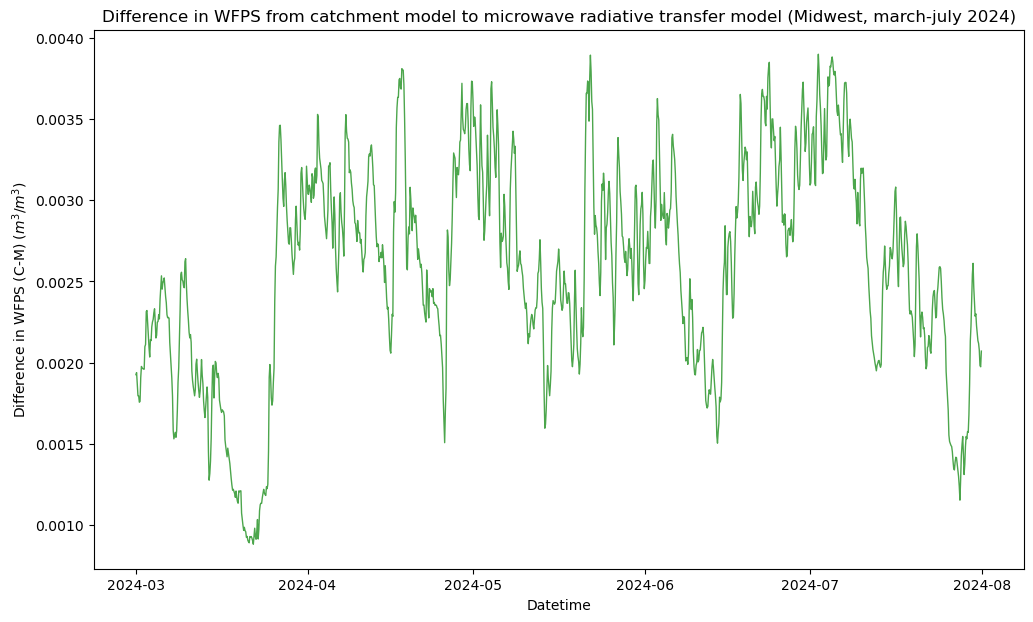

In [39]:
fig, ax1 = plt.subplots(figsize=(12, 7))
regional_mean = sm_poros_df.groupby('datetime_x')[['WFPS_c', 'WFPS_m','WFPS_diff']].mean().reset_index()
ax1.plot(regional_mean['datetime_x'], regional_mean['WFPS_diff'], label='WFPS Difference', color='green', alpha=0.7,lw=1)
ax1.set_xlabel('Datetime')
ax1.set_ylabel(r'Difference in WFPS (C-M) ($m^3/m^3$)') 
plt.title('Difference in WFPS from catchment model to microwave radiative transfer model (Midwest, march-july 2024)')

### Making a parquet file with land model constants
will include 
* clsm_poros
* mwrtm_poros
* cell_lat
* cell_lon
* time

In [40]:
midwest_porosity_df

,latitude,longitude,catchment_model_porosity,microwave_model_porosity,datetime,diff_c-m
764302,48.951267,-103.957474,0.3963,0.4351,2025-02-14 23:58:55,-0.0388
764303,48.951267,-103.864113,0.4352,0.4584,2025-02-14 23:58:55,-0.0232
764304,48.951267,-103.770752,0.4352,0.4584,2025-02-14 23:58:55,-0.0232
764305,48.951267,-103.677391,0.4352,0.4584,2025-02-14 23:58:55,-0.0232
764306,48.951267,-103.584030,0.4352,0.4584,2025-02-14 23:58:55,-0.0232
...,...,...,...,...,...,...
1285114,36.070938,-80.430504,0.4942,0.4063,2025-02-14 23:58:55,0.0879
1285115,36.070938,-80.337143,0.4942,0.4063,2025-02-14 23:58:55,0.0879
1285116,36.070938,-80.243782,0.4554,0.4457,2025-02-14 23:58:55,0.0097
1285117,36.070938,-80.150421,0.5463,0.4063,2025-02-14 23:58:55,0.1400


In [41]:
sm_poros_df

,latitude,longitude,sm_surface,sm_rootzone,surface_temp,soil_temp_layer1,LAI,datetime_x,catchment_model_porosity,microwave_model_porosity,diff_c-m,WFPS_c,WFPS_m,WFPS_diff
0,48.951267,-103.957474,0.087287,0.119180,282.964539,273.160004,0.042725,2024-02-29 22:28:55,0.3963,0.4351,-0.0388,0.220254,0.200613,0.019641
1,48.951267,-103.864113,0.158729,0.200062,282.894318,273.160004,0.036697,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.364726,0.346267,0.018459
2,48.951267,-103.770752,0.160134,0.201959,282.958588,273.160004,0.030681,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.367954,0.349332,0.018622
3,48.951267,-103.677391,0.159644,0.203763,282.922485,273.160004,0.029179,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.366829,0.348264,0.018566
4,48.951267,-103.584030,0.159519,0.203495,282.843567,273.160004,0.029720,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.366541,0.347990,0.018551
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39952145,36.070938,-80.430504,0.279432,0.318316,302.558807,301.026520,3.516579,2024-07-31 22:28:55,0.4942,0.4063,0.0879,0.565423,0.687748,-0.122325
39952146,36.070938,-80.337143,0.292319,0.306735,302.554413,301.201599,1.901240,2024-07-31 22:28:55,0.4942,0.4063,0.0879,0.591499,0.719466,-0.127967
39952147,36.070938,-80.243782,0.277417,0.295555,303.147797,302.106262,1.140026,2024-07-31 22:28:55,0.4554,0.4457,0.0097,0.609172,0.622430,-0.013258
39952148,36.070938,-80.150421,0.333433,0.362370,302.553680,301.206207,1.942417,2024-07-31 22:28:55,0.5463,0.4063,0.1400,0.610348,0.820658,-0.210310


In [42]:
output_file = '/global/scratch/users/toireasamarie/SMAP/midwest_soil_moisture_poros_WFPS.parquet'
sm_poros_df.to_parquet(output_file, engine='pyarrow')

In [43]:
test_df = pd.read_parquet(output_file, engine='pyarrow')
test_df

,latitude,longitude,sm_surface,sm_rootzone,surface_temp,soil_temp_layer1,LAI,datetime_x,catchment_model_porosity,microwave_model_porosity,diff_c-m,WFPS_c,WFPS_m,WFPS_diff
0,48.951267,-103.957474,0.087287,0.119180,282.964539,273.160004,0.042725,2024-02-29 22:28:55,0.3963,0.4351,-0.0388,0.220254,0.200613,0.019641
1,48.951267,-103.864113,0.158729,0.200062,282.894318,273.160004,0.036697,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.364726,0.346267,0.018459
2,48.951267,-103.770752,0.160134,0.201959,282.958588,273.160004,0.030681,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.367954,0.349332,0.018622
3,48.951267,-103.677391,0.159644,0.203763,282.922485,273.160004,0.029179,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.366829,0.348264,0.018566
4,48.951267,-103.584030,0.159519,0.203495,282.843567,273.160004,0.029720,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.366541,0.347990,0.018551
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39952145,36.070938,-80.430504,0.279432,0.318316,302.558807,301.026520,3.516579,2024-07-31 22:28:55,0.4942,0.4063,0.0879,0.565423,0.687748,-0.122325
39952146,36.070938,-80.337143,0.292319,0.306735,302.554413,301.201599,1.901240,2024-07-31 22:28:55,0.4942,0.4063,0.0879,0.591499,0.719466,-0.127967
39952147,36.070938,-80.243782,0.277417,0.295555,303.147797,302.106262,1.140026,2024-07-31 22:28:55,0.4554,0.4457,0.0097,0.609172,0.622430,-0.013258
39952148,36.070938,-80.150421,0.333433,0.362370,302.553680,301.206207,1.942417,2024-07-31 22:28:55,0.5463,0.4063,0.1400,0.610348,0.820658,-0.210310
